# 제주도 관광지 방문 경험 조사

제주도 관광지 중 어떤 곳을 많이 방문했는지 알아보기 위해 Google 설문을 만들었다. 방문지를 여러 곳 고를 수 있도록 질문 유형을 체크박스로 설정했다. 2026년 11월 25일에 스프레드시트에 저장된 실제 응답 7건을 분석했다.

- [Google 설문 응답 화면](https://docs.google.com/forms/d/e/1FAIpQLSf7D9j37OqrmrMD0UpEJmfUNHiC-2pxMQTeVNwwu3IuhsdQHg/viewform)
- [Google 스프레드시트](https://docs.google.com/spreadsheets/d/1wIVMn33Hs1kbzhUqBLJ057LKAJ2EEueQ8Wk-1-s1lkQ/edit?gid=563284489#gid=563284489)
- 압축 파일 안의 Excel에서 같은 날짜의 응답 집계와 막대그래프를 확인할 수 있다.
- Colab에서 실행할 때는 왼쪽 파일 패널에 `실제 응답.csv`, `관광지 좌표.csv`, `제주 지도 자료.json`을 올리고 맨 위 셀부터 실행한다.

In [ ]:
%pip install pandas matplotlib koreanize-matplotlib folium

## 1. 응답 CSV 읽기

Google 스프레드시트의 설문 응답 탭에서 방문지 열을 가져와 CSV로 저장했다. 제출용 CSV에는 분석에 사용한 방문지 응답만 넣었다. 강의자료 80쪽의 `read_csv()`로 파일을 읽었다.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import folium

folder = Path.cwd()
file_name = "실제 응답.csv"
data_label = "실제 응답"
places = ["성산일출봉", "한라산", "협재해수욕장", "천지연폭포", "섭지코지"]
none_option = "보기 중 방문한 곳 없음"

df = pd.read_csv(folder / file_name, encoding="utf-8-sig")
answers = df["방문한 제주도 관광지"].dropna().astype(str).str.strip()
answers = answers[answers != ""]
print(f"{data_label} {len(answers)}건")

실제 응답 7건


## 2. 복수 선택 집계하기

체크박스 응답은 한 셀에 쉼표로 이어져 있다. 응답을 관광지 단위로 나눈 다음 강의자료 33쪽의 `value_counts()`로 빈도를 구했다. ‘보기 중 방문한 곳 없음’은 그 항목만 고른 응답을 따로 세었다.

In [3]:
choices = answers.str.split(",").map(
    lambda values: list(dict.fromkeys(value.strip() for value in values if value.strip()))
)
selected = choices.explode()
unknown = set(selected.dropna()) - set(places) - {none_option}
if unknown:
    raise ValueError(f"설문 보기에 없는 값: {sorted(unknown)}")

summary = selected.value_counts().reindex(places, fill_value=0)
summary = summary.sort_values(ascending=False, kind="stable")
summary = summary.rename_axis("관광지").reset_index(name="방문 인원")
none_count = int(choices.map(lambda values: values == [none_option]).sum())
print(summary.to_string(index=False))
print(f"관광지 선택 합계: {summary['방문 인원'].sum()}회")
print(f"보기 중 방문한 곳 없음만 선택: {none_count}명")

   관광지  방문 인원
협재해수욕장      7
   한라산      5
 성산일출봉      2
  섭지코지      2
 천지연폭포      1
관광지 선택 합계: 17회
보기 중 방문한 곳 없음만 선택: 0명


## 3. 막대그래프 그리기

강의자료 38쪽의 막대그래프와 106쪽의 한글 글꼴 설정을 적용했다. 방문 인원은 협재해수욕장 7명, 한라산 5명, 성산일출봉 2명, 섭지코지 2명, 천지연폭포 1명이었다. 한 사람이 여러 곳을 고를 수 있어서 응답자 7명의 관광지 선택을 합하면 17회가 된다.

이번 설문에서는 협재해수욕장을 고른 사람이 가장 많았다. 응답자가 7명이므로 전체 제주 관광객의 방문 순위까지 판단하기는 어렵다.

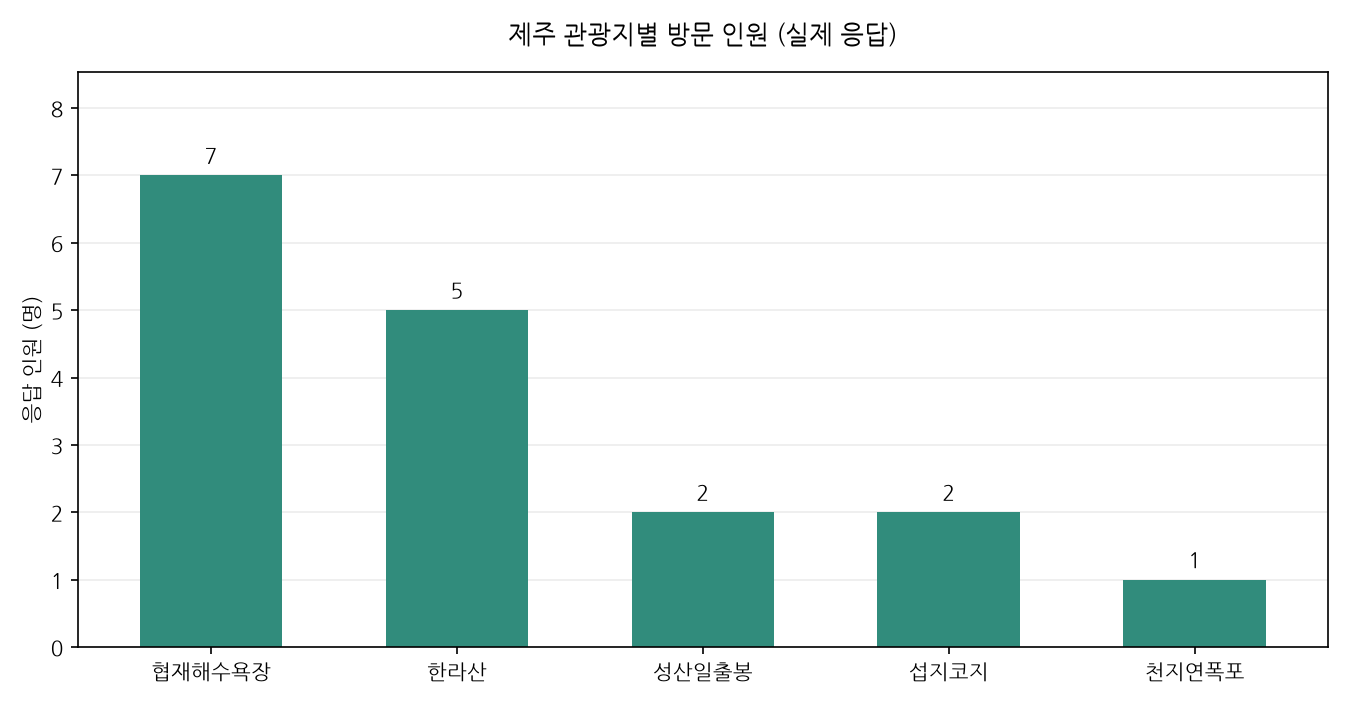

In [4]:
ax = summary.plot.bar(
    x="관광지", y="방문 인원", color="#318c7c", legend=False,
    rot=0, figsize=(9, 4.7), width=0.58,
)
ax.set_title(f"제주 관광지별 방문 인원 ({data_label})", pad=14)
ax.set_ylabel("응답 인원 (명)")
ax.set_xlabel("")
ax.set_ylim(0, max(1, summary["방문 인원"].max()) * 1.22)
ax.bar_label(ax.containers[0], padding=4)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.23)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(folder / f"제주 방문지 막대그래프 ({data_label}).png", dpi=150)
plt.show()

## 4. 지오코딩으로 좌표 구하기

[Photon](https://github.com/komoot/photon)에서 제주도 범위로 관광지 이름을 검색했다. 같은 이름의 정류장이나 편의시설이 함께 나오면 관광지 유형을 확인했다. 협재해수욕장은 해변, 천지연폭포는 폭포로 분류된 좌표를 사용했다. 조회한 좌표는 CSV로 저장했다. `refresh_locations`를 `True`로 바꾸면 다시 조회한다. 좌표 출처는 [OpenStreetMap 기여자](https://www.openstreetmap.org/copyright)다.

In [5]:
import json
from urllib.parse import urlencode
from urllib.request import urlopen

def geocode(name, kind):
    params = {"q": name, "limit": 8, "bbox": "126.12,33.13,127.02,33.6"}
    with urlopen("https://photon.komoot.io/api/?" + urlencode(params), timeout=12) as response:
        features = json.load(response)["features"]

    for feature in features:
        props = feature["properties"]
        same_name = props.get("name", "").replace(" ", "") == name.replace(" ", "")
        if same_name and props.get("state") == "제주특별자치도" and props.get("osm_value") == kind:
            lon, lat = feature["geometry"]["coordinates"]
            if 33.13 <= lat <= 33.60 and 126.12 <= lon <= 127.02:
                source = f"https://www.openstreetmap.org/node/{props['osm_id']}"
                return [name, kind, lat, lon, source]
    raise ValueError(f"제주도에서 확인할 수 없는 관광지: {name}")

refresh_locations = False
coordinate_file = folder / "관광지 좌표.csv"
types = ["peak", "volcano", "beach", "waterfall", "attraction"]
if refresh_locations or not coordinate_file.exists():
    locations = pd.DataFrame(
        [geocode(name, kind) for name, kind in zip(places, types)],
        columns=["관광지", "유형", "위도", "경도", "OSM 출처"],
    )
    locations.to_csv(coordinate_file, index=False, encoding="utf-8-sig")
else:
    locations = pd.read_csv(coordinate_file, encoding="utf-8-sig")
print(locations[["관광지", "위도", "경도"]].to_string(index=False))

   관광지        위도         경도
 성산일출봉 33.458889 126.940818
   한라산 33.361431 126.529419
협재해수욕장 33.395112 126.240280
 천지연폭포 33.246927 126.554528
  섭지코지 33.424041 126.930731


## 5. 제주도 지도에 관광지 표시하기

Natural Earth의 제주 해안선 위에 Photon에서 조회한 관광지 좌표 5개를 표시했다. 마커를 누르면 위도와 경도가 나온다. 해안선과 지도 표시 라이브러리를 HTML 안에 넣어서 생성된 파일을 인터넷 연결 없이도 브라우저에서 열 수 있다.

[Natural Earth 해안선 데이터](https://www.naturalearthdata.com/downloads/10m-physical-vectors/)

In [6]:
from html import escape
import re

# 해안선과 지도 라이브러리를 HTML 안에 넣어 로컬에서도 열 수 있게 한다.
assets = json.loads((folder / "제주 지도 자료.json").read_text(encoding="utf-8"))
jeju_map = folium.Map(location=[33.38, 126.55], zoom_start=10, tiles=None)
jeju_map.default_js = []
jeju_map.default_css = []

folium.GeoJson(
    assets["coastline"],
    style_function=lambda _: {
        "fillColor": "#dce9d5", "fillOpacity": 1,
        "color": "#749373", "weight": 1.3,
    },
).add_to(jeju_map)

for _, row in locations.iterrows():
    name = escape(row["관광지"])
    lat, lon = row["위도"], row["경도"]
    popup = folium.Popup(f"<b>{name}</b><br>위도 {lat:.6f}<br>경도 {lon:.6f}", max_width=250)
    icon = folium.DivIcon(class_name="jeju-marker", icon_size=(18, 18), icon_anchor=(9, 9))
    direction = "left" if name == "성산일출봉" else "right"
    label = folium.Tooltip(name, permanent=True, direction=direction)
    folium.Marker([lat, lon], tooltip=label, popup=popup, icon=icon, title=name).add_to(jeju_map)

jeju_map.fit_bounds([[33.16, 126.12], [33.57, 126.99]], padding=[24, 32], max_zoom=11)
style = """
.leaflet-container {background:#dceef5; font-family:system-ui,sans-serif}
.jeju-marker {background:#2459a1; border:2px solid white; border-radius:50%;
              box-shadow:0 1px 4px #365572; cursor:pointer; box-sizing:border-box}
.leaflet-tooltip {font:600 13px system-ui,sans-serif; color:#18324a; padding:4px 7px}
.map-title {position:absolute; z-index:1000; top:16px; left:50%; transform:translateX(-50%);
            margin:0; padding:9px 14px; background:#fff; border-radius:8px;
            color:#18324a; font:700 18px system-ui,sans-serif; white-space:nowrap}
.map-source {position:absolute; z-index:1000; bottom:0; left:0; background:#ffffffe6;
             padding:2px 6px; color:#18324a; font:11px system-ui,sans-serif}
"""
page = jeju_map.get_root()
page.header.add_child(folium.Element(
    "<title>제주 관광지 지도</title><style>" + assets["leaflet_css"] + style + "</style>"
    "<script>" + assets["leaflet_js"] + "\nL.Marker.mergeOptions({icon:L.divIcon()});</script>"
    "<script>" + assets["jquery_js"] + "</script>"
    "<!--\n" + assets["licenses"] + "\n-->"
))
page.html.add_child(folium.Element(
    '<h1 class="map-title">제주 관광지 지도</h1>'
    '<div class="map-source">해안선 Natural Earth · '
    '좌표 © <a href="https://www.openstreetmap.org/copyright">OpenStreetMap 기여자</a> / Photon</div>'
))
map_html = page.render().replace("<html>", '<html lang="ko">', 1)
# 사용하지 않는 Folium 기본 아이콘 글꼴의 원격 URL을 제거한다.
map_html = re.sub(r"<style>/\*\s*\* Glyphicons Halflings.*?</style>", "", map_html, flags=re.S)
map_file = folder / "제주 관광지 지도.html"
map_file.write_text(map_html, encoding="utf-8")
from IPython.display import IFrame, display
map_preview = IFrame("about:blank", width="100%", height=500, extras=[
    'title="제주 관광지 지도"',
    'srcdoc="' + escape(map_html, quote=True) + '"',
])
display(map_preview)


<iframe
 width="100%"
 height="500"
 src="about:blank"
 frameborder="0"
 allowfullscreen
 referrerpolicy="strict-origin-when-cross-origin"
 title="제주 관광지 지도" srcdoc="<!DOCTYPE html>
<html lang="ko">
<head>
 
 <meta http-equiv="content-type" content="text/html; charset=UTF-8" />
 <title>제주 관광지 지도</title><style>/* required styles */

.leaflet-pane,
.leaflet-tile,
.leaflet-marker-icon,
.leaflet-marker-shadow,
.leaflet-tile-container,
.leaflet-pane > svg,
.leaflet-pane > canvas,
.leaflet-zoom-box,
.leaflet-image-layer,
.leaflet-layer {
	position: absolute;
	left: 0;
	top: 0;
	}
.leaflet-container {
	overflow: hidden;
	}
.leaflet-tile,
.leaflet-marker-icon,
.leaflet-marker-shadow {
	-webkit-user-select: none;
 -moz-user-select: none;
 user-select: none;
 -webkit-user-drag: none;
	}
/* Prevents IE11 from highlighting tiles in blue */
.leaflet-tile::selection {
	background: transparent;
}
/* Safari renders non-retina tile on retina better with this, but Chrome is worse */
.leaflet-safari .leaflet-tile {
	image-rendering: -webkit-optimize-contrast;
	}
/* hack that prevents hw layers "stretching" when loading new tiles */
.leaflet-safari .leaflet-tile-container {
	width: 1600px;
	height: 1600px;
	-webkit-transform-origin: 0 0;
	}
.leaflet-marker-icon,
.leaflet-marker-shadow {
	display: block;
	}
/* .leaflet-container svg: reset svg max-width decleration shipped in Joomla! (joomla.org) 3.x */
/* .leaflet-container img: map is broken in FF if you have max-width: 100% on tiles */
.leaflet-container .leaflet-overlay-pane svg {
	max-width: none !important;
	max-height: none !important;
	}
.leaflet-container .leaflet-marker-pane img,
.leaflet-container .leaflet-shadow-pane img,
.leaflet-container .leaflet-tile-pane img,
.leaflet-container img.leaflet-image-layer,
.leaflet-container .leaflet-tile {
	max-width: none !important;
	max-height: none !important;
	width: auto;
	padding: 0;
	}

.leaflet-container img.leaflet-tile {
	/* See: https://bugs.chromium.org/p/chromium/issues/detail?id=600120 */
	mix-blend-mode: plus-lighter;
}

.leaflet-container.leaflet-touch-zoom {
	-ms-touch-action: pan-x pan-y;
	touch-action: pan-x pan-y;
	}
.leaflet-container.leaflet-touch-drag {
	-ms-touch-action: pinch-zoom;
	/* Fallback for FF which doesn't support pinch-zoom */
	touch-action: none;
	touch-action: pinch-zoom;
}
.leaflet-container.leaflet-touch-drag.leaflet-touch-zoom {
	-ms-touch-action: none;
	touch-action: none;
}
.leaflet-container {
	-webkit-tap-highlight-color: transparent;
}
.leaflet-container a {
	-webkit-tap-highlight-color: rgba(51, 181, 229, 0.4);
}
.leaflet-tile {
	filter: inherit;
	visibility: hidden;
	}
.leaflet-tile-loaded {
	visibility: inherit;
	}
.leaflet-zoom-box {
	width: 0;
	height: 0;
	-moz-box-sizing: border-box;
 box-sizing: border-box;
	z-index: 800;
	}
/* workaround for https://bugzilla.mozilla.org/show_bug.cgi?id=888319 */
.leaflet-overlay-pane svg {
	-moz-user-select: none;
	}

.leaflet-pane { z-index: 400; }

.leaflet-tile-pane { z-index: 200; }
.leaflet-overlay-pane { z-index: 400; }
.leaflet-shadow-pane { z-index: 500; }
.leaflet-marker-pane { z-index: 600; }
.leaflet-tooltip-pane { z-index: 650; }
.leaflet-popup-pane { z-index: 700; }

.leaflet-map-pane canvas { z-index: 100; }
.leaflet-map-pane svg { z-index: 200; }

.leaflet-vml-shape {
	width: 1px;
	height: 1px;
	}
.lvml {
	behavior: url(#default#VML);
	display: inline-block;
	position: absolute;
	}


/* control positioning */

.leaflet-control {
	position: relative;
	z-index: 800;
	pointer-events: visiblePainted; /* IE 9-10 doesn't have auto */
	pointer-events: auto;
	}
.leaflet-top,
.leaflet-bottom {
	position: absolute;
	z-index: 1000;
	pointer-events: none;
	}
.leaflet-top {
	top: 0;
	}
.leaflet-right {
	right: 0;
	}
.leaflet-bottom {
	bottom: 0;
	}
.leaflet-left {
	left: 0;
	}
.leaflet-control {
	float: left;
	clear: both;
	}
.leaflet-right .leaflet-control {
	float: right;
	}
.leaflet-top .leaflet-control {
	margin-top: 10px;
	}
.leaflet-bottom .leaflet-control